# 3. Progress

> **Overview.** Prior success counts the LTUs that help, but not how much they help. A more direct heuristic: if new
> inputs recently decreased an output's error, one more new input will probably decrease it further. Can search draw
> parents by this expected decrease despite the noise in its measure, and stay near uniform parents where the
> heuristic is wrong?

**Setup.** Notebook 1's learner and problem. Each new LTU gets a parent output, drawn:
- uniformly (baseline: the current method);
- by prior success, as in notebook 2;
- **by progress** (proposed): in proportion to the output's priority plus the mean priority over the outputs. Thus
  half of the new LTUs get uniform parents, and all of them do if all the priorities are 0. The priority is the
  expected decrease in error from one more new input, $\max(M_o - L_o, 0) / M_o \cdot L_o / n_o$: the fraction of the
  error removed recently, times the error left, divided by the new inputs. $L_o$ and $M_o$ are the output's mean
  absolute errors with weights that decay with time constants of 10k and 80k steps: the search period, and the time
  that search takes to replace all the LTUs. $n_o$ counts the output's new LTUs, and the 401 inputs of the linear
  learner (400 inputs and the bias) as new at step 0, with weights that decay with a time constant of 80k steps (at
  least 1);
- **by gated progress** (proposed): the same, but the priority is 0 at each step where $M_o - L_o$ is not more than 3
  standard errors;
- by an oracle, as in notebook 1 (reference).

5 seeds; 600k steps.

In [1]:
import os
import pickle
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 20
N_LEARNABLE = 2                      # the first outputs, each reading target LTUs; the rest are decoys
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # noise on the outputs that read target LTUs: the lowest RMSE possible
N_CHANGES = 4                        # changes: a decoy becomes a target, reading N_NEW new target LTUs
FIRST_CHANGE, CHANGE_EVERY = 200_000, 100_000
N_NEW = 2
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 160
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 20                        # LTUs replaced at each search step, the least useful
HELP_Z = 3.0                         # an LTU helps if its removal would raise its parent's error by this many standard
                                     # errors
SIGNIFICANT_Z = 3.0                  # a decrease in error is significant above this many standard errors

# --- Experiment ---
NUM_STEPS = 600_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
DECAY = 1 - 1 / PERIOD               # factor by which the sums of the statistics decay at each step
SLOW = 1 - REPLACED / (N_LTUS * PERIOD)   # the same for the slow error sums: as fast as search replaces all LTUs
UNIFORM, PRIOR_SUCCESS, PROGRESS, GATED, ORACLE = range(5)   # how a new LTU's parent output is drawn
NOISE, NOISY_LINEAR = range(2)                             # kinds of decoy

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, N_OUTPUTS, N_ALL_TARGETS): the outputs' weights on them, by version
    linear: jax.Array           # (N_CHANGES + 1, N_OUTPUTS, N_INPUTS): the decoys' linear weights, by version
    noise_std: jax.Array        # (N_CHANGES + 1, N_OUTPUTS): each output's noise, by version


def make_target(key, kind, noise_std):
    # Version 0: the first N_LEARNABLE outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise of std noise_std. The others (decoys) are noise
    # of std 1, plus, if kind is NOISY_LINEAR, a linear function of N_SOURCES random inputs (its own, drawn for every
    # output) with random +-1 weights scaled to unit variance. Each target LTU reads N_SOURCES random inputs, with random
    # +-1 weights. Change c makes version c + 1: a decoy, at random, reads the next N_NEW target LTUs instead, with
    # noise of std noise_std.
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(N_OUTPUTS)[:, None] < N_LEARNABLE
    reads = jnp.pad(pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (kind == NOISY_LINEAR))
    outs = [out]
    for c in range(N_CHANGES):
        sign_key, decoy_key = jax.random.split(jax.random.fold_in(change_key, c))
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        decoy = jax.random.categorical(decoy_key, jnp.log(~(out != 0).any(1)))
        out = out.at[decoy].set(jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW))
        outs.append(out)
    out = jnp.stack(outs)
    learnable = (out != 0).any(2)
    return Target(w, out, linear * ~learnable[..., None], jnp.where(learnable, noise_std, 1.0))


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear[version] @ x
               + target.noise_std[version] * jax.random.normal(noise_key, (N_OUTPUTS,)))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1], of which each output reads only its own LTUs.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (outputs, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (outputs, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (outputs,): each output's squared errors, summed with weights that decay by DECAY
    target_sum: jax.Array       # (outputs,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array
    abs_sum: jax.Array          # (outputs,): each output's absolute errors, summed likewise
    weight_sum: jax.Array       # (): the weights of these sums, summed
    removal: jax.Array          # (N_LTUS,): the rise in its parent's squared error if it were removed, summed likewise
    removal_sq: jax.Array       # (N_LTUS,): the squares of these rises, summed likewise
    age: jax.Array              # (N_LTUS,): the steps since search added it
    slow_loss_sum: jax.Array    # (outputs,): each output's squared errors, summed with weights that decay by SLOW
    slow_abs_sum: jax.Array     # (outputs,): each output's absolute errors, summed likewise
    slow_weight_sum: jax.Array  # (): the weights of these sums, summed
    weight_sq_sums: jax.Array   # (3,): the squares of the weights, of the slow weights and of their products, summed
    new_ltus: jax.Array         # (outputs,): its new LTUs, counted with weights that decay by SLOW
    new_linear: jax.Array       # (): each output's new linear inputs and bias, N_INPUTS + 1 at first, decaying by SLOW


def init_net(key):
    # N_LTUS new LTUs with uniform parents, reading random inputs with random signs (no output has weights yet); every
    # other weight 0.
    w = {'hidden': jnp.zeros((N_LTUS, N_INPUTS + 1)), 'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    zero, units = jnp.zeros(N_OUTPUTS), jnp.zeros(N_LTUS)
    net = Net(w, jnp.zeros(w['hidden'].shape, bool), OPTIMIZER.init(w), stats, jnp.zeros((N_OUTPUTS, N_LTUS)),
              jnp.zeros((N_LTUS, N_INPUTS)), zero, zero, zero, zero, jnp.zeros(()), units, units, units, zero, zero,
              jnp.zeros(()), jnp.zeros(3), zero, jnp.array(N_INPUTS + 1.0))
    return rewire(net, key, jnp.ones(N_LTUS, bool), jnp.zeros(N_OUTPUTS), False, False)


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh. Its parent's count of new LTUs goes up by 1.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow,
                        candidates=jnp.where(replaced[:, None], 0.0, net.candidates),
                        new_ltus=net.new_ltus + ((shadow != 0) & replaced).sum(1))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each output reading only
    # its own LTUs, and each LTU's shadow weight standing in for its weight to its parent in the backward pass while the
    # real one is smaller than 1 in magnitude. Returns the new network and each output's squared error on this sample,
    # before learning from it. After the sums decay, adds the squared and absolute errors to the error sums, the
    # targets and their squares to target_sum and target_sq_sum, 1 to the weight sums, dL/dz * x_i to each LTU's
    # gradient sums, and to `removal` (and its square to `removal_sq`) the rise in its parent's squared error if its
    # part of the prediction were removed; decays the counts of new LTUs and new linear inputs. `probe` is zero; its
    # gradients are the error arriving at each LTU and dL/dz.
    feeds = net.shadow != 0
    mask = jnp.concatenate([jnp.ones((N_OUTPUTS, N_INPUTS), bool), feeds, jnp.ones((N_OUTPUTS, 1), bool)], 1)

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        a = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean) + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where(feeds & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(a), mean,
                                                      jax.lax.stop_gradient(prediction - y))

    (_, (source, h, mean, residual)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * mask}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': source * mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    parent_residual = jnp.abs(net.shadow).T @ residual
    rise = (parent_residual - net.w['output'][:, N_INPUTS:-1].sum(0) * h) ** 2 - parent_residual ** 2
    squared, absolute = residual ** 2, jnp.abs(residual)
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=DECAY * net.loss_sum + squared,
                        target_sum=DECAY * net.target_sum + y, target_sq_sum=DECAY * net.target_sq_sum + y ** 2,
                        abs_sum=DECAY * net.abs_sum + absolute, weight_sum=DECAY * net.weight_sum + 1,
                        removal=DECAY * net.removal + rise, removal_sq=DECAY * net.removal_sq + rise ** 2,
                        age=net.age + 1, slow_loss_sum=SLOW * net.slow_loss_sum + squared,
                        slow_abs_sum=SLOW * net.slow_abs_sum + absolute,
                        slow_weight_sum=SLOW * net.slow_weight_sum + 1,
                        weight_sq_sums=jnp.array([DECAY ** 2, SLOW ** 2, DECAY * SLOW]) * net.weight_sq_sums + 1,
                        new_ltus=SLOW * net.new_ltus, new_linear=SLOW * net.new_linear), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's squared weight to its parent, its only output: about the increase in its parent's squared error if it
    # were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def helps(net):
    # (N_LTUS,): whether the mean of the rises in its parent's squared error if it were removed, weighted as in their
    # sums, is more than HELP_Z standard errors: the standard deviation of the rises times sqrt(n2) / n, with n the sum
    # of the weights and n2 the sum of their squares.
    n = (1 - DECAY ** net.age) / (1 - DECAY)
    n2 = (1 - DECAY ** (2 * net.age)) / (1 - DECAY ** 2)
    mean = net.removal / jnp.maximum(n, 1)
    variance = jnp.maximum(net.removal_sq / jnp.maximum(n, 1) - mean ** 2, 0.0)
    return net.removal > HELP_Z * jnp.sqrt(variance * n2)


def spread(net):
    # The sum of the squared differences between the normalized weights of the sums weighted by DECAY and by SLOW: the
    # variance of the difference of their means, divided by the variance of the summed values.
    squares, slow_squares, products = net.weight_sq_sums
    return jnp.maximum(squares / net.weight_sum ** 2 + slow_squares / net.slow_weight_sum ** 2
                       - 2 * products / (net.weight_sum * net.slow_weight_sum), 0.0)


def priority(net, rule):
    # (outputs,): each output's priority, the expected decrease in its error from one more new input: (M - L) / M, the
    # fraction of its error removed recently, divided by its count of new LTUs and new linear inputs (at least 1),
    # times L, the error left, with L and M its mean absolute errors weighted by DECAY and by SLOW. 0 if negative
    # (PROGRESS), or if M - L is not more than SIGNIFICANT_Z standard errors (GATED). 0 for the other rules.
    fast, slow = net.abs_sum / net.weight_sum, net.slow_abs_sum / net.slow_weight_sum
    progress = (slow - fast) / slow / jnp.maximum(net.new_ltus + net.new_linear, 1.0) * fast
    variance = jnp.maximum(net.slow_loss_sum / net.slow_weight_sum - slow ** 2, 0.0)   # of the absolute errors
    noise = jnp.sqrt(variance * spread(net))                                          # the standard error of M - L
    return jnp.select([rule == PROGRESS, rule == GATED],
                      [jnp.maximum(progress, 0.0), jnp.where(slow - fast > SIGNIFICANT_Z * noise, progress, 0.0)],
                      jnp.zeros_like(fast))


def parent_logits(net, rule, learnable):
    # Log-probabilities of each output being a new LTU's parent, up to a constant: uniform; in proportion to
    # (H + e + p) / (N + 2), with N its LTUs, H those that help it, e = (V - L) / V its explained fraction, L its mean
    # squared error and V its targets' variance, weighted as in their sums, e 0 if negative, and p the share of all
    # LTUs that help their parent (PRIOR_SUCCESS); in proportion to its priority plus the mean priority (PROGRESS, GATED); or in proportion to L,
    # among only the outputs reading target LTUs (ORACLE). Uniform if all are 0.
    loss = net.loss_sum / net.weight_sum
    variance = net.target_sq_sum / net.weight_sum - (net.target_sum / net.weight_sum) ** 2
    explained = jnp.maximum(variance - loss, 0.0) / jnp.maximum(variance, 1e-30)
    ltus = jnp.abs(net.shadow)
    helpers = ltus @ helps(net)
    progress = priority(net, rule)
    weight = jnp.select([rule == PRIOR_SUCCESS, rule == ORACLE],
                        [(helpers + explained + helpers.sum() / N_LTUS) / (ltus.sum(1) + 2), loss * learnable],
                        progress + progress.mean())
    return jnp.log(jnp.where(weight.sum() > 0, weight, 1.0))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after. The LTUs grow every WINDOW steps, and every PERIOD steps search replaces the REPLACED
    # least useful LTUs by new ones with parents drawn by `rule`. Returns, for each window, the mean squared error over
    # the outputs then reading target LTUs, and the mean priority at the end of the window of three kinds of output:
    # the outputs reading target LTUs from the start, the decoys that have become targets, and the decoys.
    first = (target.out[0] != 0).any(1)

    def window(net, inputs):
        index, key = inputs
        version = jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES)
        learnable = (target.out[version] != 0).any(1)
        sample_key, wire_key = jax.random.split(key)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                    jax.random.split(sample_key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        new = rewire(net, wire_key, weakest, parent_logits(net, rule, learnable), True, True)
        new = new._replace(removal=jnp.where(weakest, 0.0, new.removal),
                           removal_sq=jnp.where(weakest, 0.0, new.removal_sq), age=jnp.where(weakest, 0, new.age))
        net = pick((index + 1) * WINDOW % PERIOD == 0, new, net)
        mean = lambda values, kind: (values * kind).sum() / kind.sum()
        now = priority(net, rule)
        kinds = (first, learnable & ~first, ~learnable)
        return net, (mean(squared.mean(0), learnable), *(mean(now, kind) for kind in kinds))

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (decoy kind, noise std, rule) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the same
    # target LTUs and inputs. Returns {config: the RMSE over the outputs then reading target LTUs, (seed, window)} and
    # {config: the mean priorities of the three kinds of output of train, (3, seed, window)}.
    kind, noise, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2), kind, noise)
    mse, *kinds = (np.asarray(v).reshape(len(configs), N_SEEDS, -1)
                   for v in jax.jit(jax.vmap(train))(jax.vmap(init_net)(keys(0)), keys(1), targets, rule))
    return dict(zip(configs, np.sqrt(mse))), dict(zip(configs, np.stack(kinds, 1)))

## Runs

In [6]:
DECOYS = [(NOISE, 'noise decoys'), (NOISY_LINEAR, 'noisy linear decoys')]
RULES = [('uniform', 'baseline: current method', UNIFORM, 'tab:red'),
         ('prior success', 'notebook 2', PRIOR_SUCCESS, 'tab:blue'),
         ('progress', 'proposed', PROGRESS, 'tab:purple'),
         ('gated progress', 'proposed', GATED, 'tab:cyan'),
         ('oracle', 'reference: error, among only the outputs reading target LTUs', ORACLE, 'tab:gray')]
# CACHE holds {rule name: its RMSE and mean priorities, each {(decoy kind, noise std): array}}. Only the rules missing
# from it run. Delete a rule's entry after changing its code, and the file after changing shared code.
CACHE = '3_runs.pkl'
cache = pickle.load(open(CACHE, 'rb')) if os.path.exists(CACHE) else {}
new = [rule for rule in RULES if rule[0] not in cache]
if new:
    started = perf_counter()
    # One decoy kind at a time: above 90 runs, the GPU rounds differently, and the runs would not match notebooks 1 and 2.
    outs = [{**a, **b} for a, b in zip(*(run([(kind, noise, rule) for noise in NOISE_STDS for _, _, rule, _ in new])
                                          for kind, _ in DECOYS))]
    for name, _, rule, _ in new:
        cache[name] = tuple({(kind, noise): out[(kind, noise, rule)] for kind, _ in DECOYS for noise in NOISE_STDS}
                            for out in outs)
    with open(CACHE, 'wb') as f:
        pickle.dump(cache, f)
    print(f'{len(new) * len(DECOYS) * len(NOISE_STDS) * N_SEEDS} new runs in {perf_counter() - started:.0f}s')
results, priorities = ({(*key, rule): cache[name][i][key] for name, _, rule, _ in RULES for key in cache[name][i]}
                       for i in range(2))

100 new runs in 370s


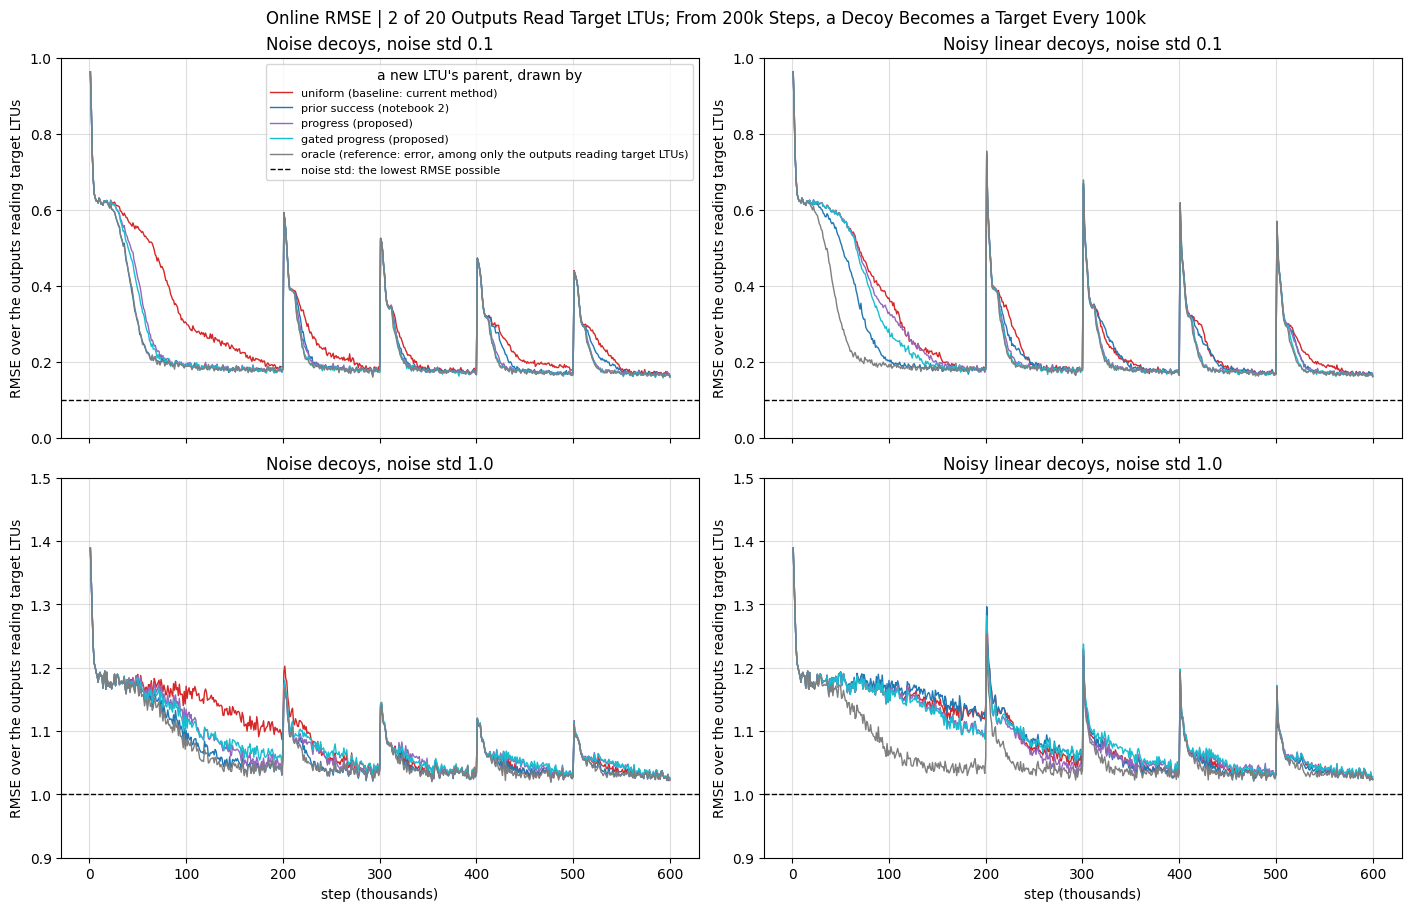

noise decoys, noise std 0.1, RMSE averaged over the run: uniform 0.284, prior success 0.241, progress 0.243, gated progress 0.239, oracle 0.234
noise decoys, noise std 1.0, RMSE averaged over the run: uniform 1.087, prior success 1.067, progress 1.077, gated progress 1.079, oracle 1.064
noisy linear decoys, noise std 0.1, RMSE averaged over the run: uniform 0.286, prior success 0.262, progress 0.273, gated progress 0.266, oracle 0.237
noisy linear decoys, noise std 1.0, RMSE averaged over the run: uniform 1.095, prior success 1.097, progress 1.092, gated progress 1.096, oracle 1.063


In [7]:
YLIMS = [(0, 1.0), (0.9, 1.5)]   # zoomed at noise std 1, where the gaps shrink near the floor
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, layout='constrained')
for column, (kind, decoys) in enumerate(DECOYS):
    for row, (noise, ylim) in enumerate(zip(NOISE_STDS, YLIMS)):
        ax = axes[row, column]
        for name, role, rule, color in RULES:
            ax.plot(STEPS / 1000, results[(kind, noise, rule)].mean(0), color=color, lw=1, label=f'{name} ({role})')
        ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
        ax.set(title=f'{decoys.capitalize()}, noise std {noise}', ylim=ylim,
               ylabel='RMSE over the outputs reading target LTUs')
        ax.grid(alpha=0.4)
for ax in axes[1]:
    ax.set(xlabel='step (thousands)')
axes[0, 0].legend(title="a new LTU's parent, drawn by", fontsize=8)
fig.suptitle('Online RMSE | 2 of 20 Outputs Read Target LTUs; From 200k Steps, a Decoy Becomes a Target Every 100k')
plt.show()

for kind, decoys in DECOYS:
    for noise in NOISE_STDS:
        print(f'{decoys}, noise std {noise}, RMSE averaged over the run: '
              + ', '.join(f'{name} {results[(kind, noise, rule)].mean():.3f}' for name, _, rule, _ in RULES))

## Priorities

The mean priority of each kind of output at the end of each 1k-step window, for progress and for gated progress. There
are 2 outputs that need LTUs from the start and 18 decoys, so the decoys' total is 9 times their mean.

progress, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 0.000389 (0k-200k), 0.000391 (200k-600k)
progress, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-200k), 0.00276 (200k-600k)
progress, noise std 0.1, noisy linear decoys, mean priority: 3.74e-05 (0k-200k), 0.000235 (200k-600k)
progress, noise std 0.1, noise decoys, mean priority: 1.63e-05 (0k-200k), 0.00022 (200k-600k)
progress, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 0.000186 (0k-200k), 0.0005 (200k-600k)
progress, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-200k), 0.000596 (200k-600k)
progress, noise std 1.0, noisy linear decoys, mean priority: 3.69e-05 (0k-200k), 0.0002 (200k-600k)
progress, noise std 1.0, noise decoys, mean priority: 1.61e-05 (0k-200k), 0.000192 (200k-600k)


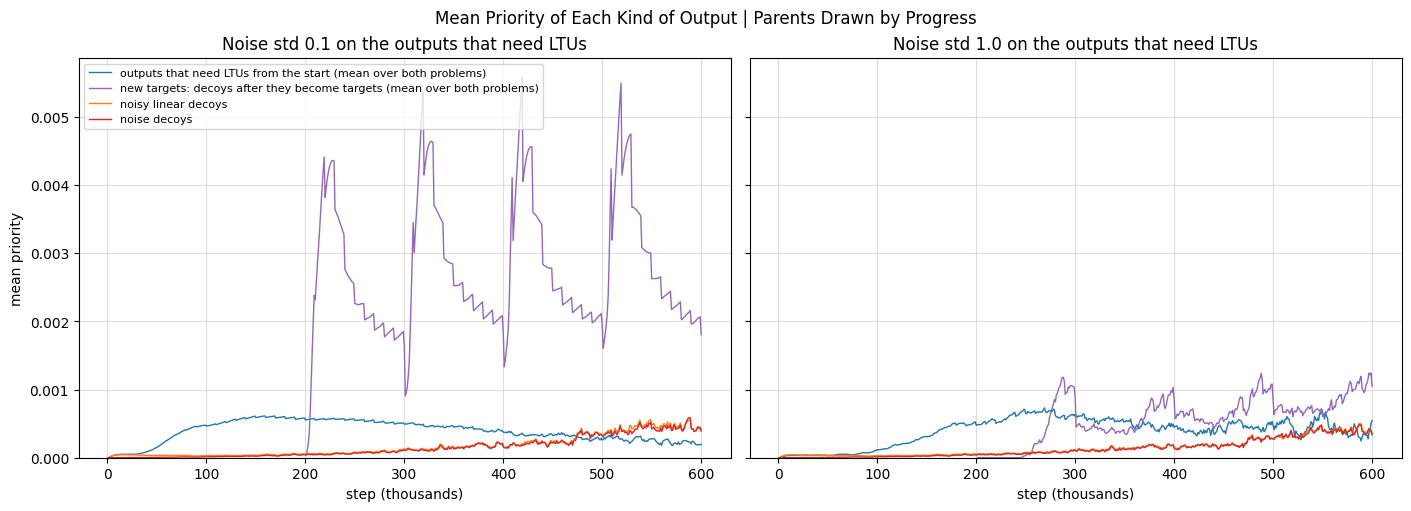

gated progress, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 0.000355 (0k-200k), 0.000276 (200k-600k)
gated progress, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-200k), 0.00233 (200k-600k)
gated progress, noise std 0.1, noisy linear decoys, mean priority: 1.03e-05 (0k-200k), 8.29e-06 (200k-600k)
gated progress, noise std 0.1, noise decoys, mean priority: 2.14e-07 (0k-200k), 6.67e-06 (200k-600k)
gated progress, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 0.000139 (0k-200k), 0.000209 (200k-600k)
gated progress, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-200k), 0.000305 (200k-600k)
gated progress, noise std 1.0, noisy linear decoys, mean priority: 1.02e-05 (0k-200k), 7.43e-06 (200k-600k)
gated progress, noise std 1.0, noise decoys, mean priority: 2.08e-07 (

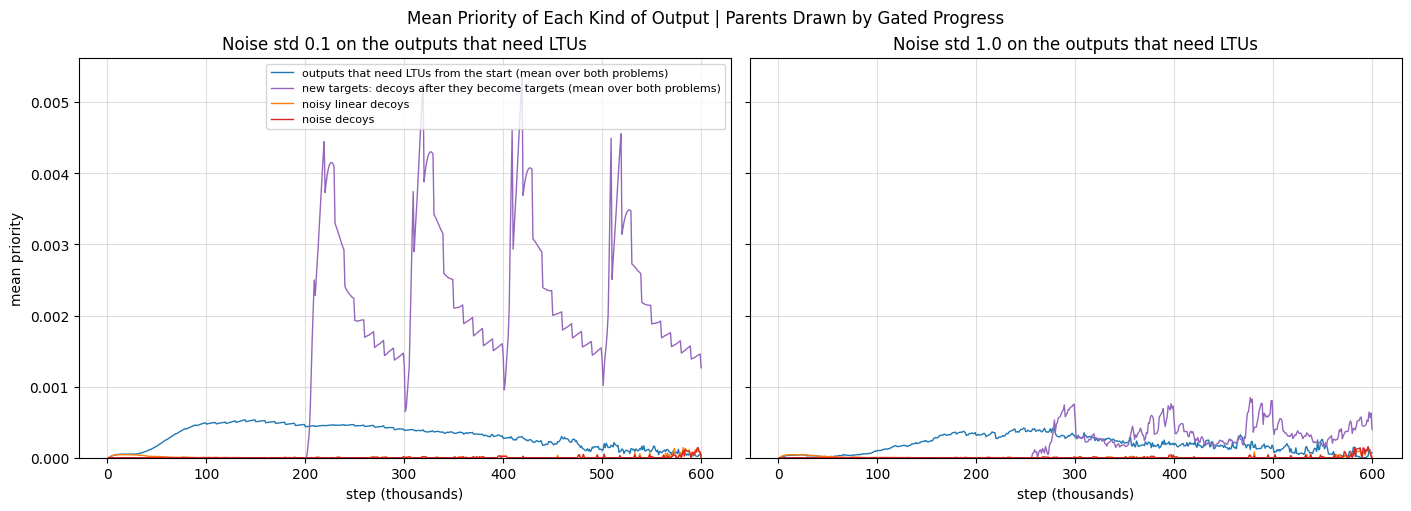

In [8]:
KINDS = [('outputs that need LTUs from the start (mean over both problems)', 'tab:blue'),
         ('new targets: decoys after they become targets (mean over both problems)', 'tab:purple'),
         ('noisy linear decoys', 'tab:orange'), ('noise decoys', 'tab:red')]
PHASES = [(0, 200), (200, 600)]   # thousands of steps
for rule_name, rule in [('Progress', PROGRESS), ('Gated Progress', GATED)]:
    fig, axes = plt.subplots(1, len(NOISE_STDS), figsize=(14, 5), sharey=True, layout='constrained')
    for ax, noise in zip(axes, NOISE_STDS):
        with_noise, with_linear = (priorities[(kind, noise, rule)].mean(1) for kind in (NOISE, NOISY_LINEAR))
        means = [(with_noise[0] + with_linear[0]) / 2, (with_noise[1] + with_linear[1]) / 2, with_linear[2],
                 with_noise[2]]   # (window,) for each kind
        for mean, (name, color) in zip(means, KINDS):
            ax.plot(STEPS / 1000, mean, color=color, lw=1, label=name)
            print(f'{rule_name.lower()}, noise std {noise}, {name}, mean priority: '
                  + ', '.join(f'{mean[a:b].mean():.3g} ({a}k-{b}k)' for a, b in PHASES))
        ax.set(title=f'Noise std {noise} on the outputs that need LTUs', xlabel='step (thousands)', ylim=(0, None))
        ax.grid(alpha=0.4)
    axes[0].set(ylabel='mean priority')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'Mean Priority of Each Kind of Output | Parents Drawn by {rule_name}')
    plt.show()

## Results

**Progress** comes close to prior success with noise decoys at noise std 0.1 (RMSE averaged over the run 0.243 against
0.241, and 0.284 for uniform parents). At noise std 1, it lies between them (1.077 against 1.067 and 1.087).

**But noise takes much of its priority** (first Priorities plot). After 200k steps, a noise decoy has about half the
mean priority of an output that needs LTUs from the start (2.2e-4 against 3.9e-4 at noise std 0.1), and the decoys'
priority rises over time. At noise std 1, the 18 decoys get more than half of the draws by priority.

**Gated progress keeps the priority away from noise** (second Priorities plot). After 200k steps, a noise decoy gets
about 30 times less priority than with progress (6.7e-6 against 2.2e-4 at noise std 0.1, and 7.5e-6 against 1.9e-4 at
noise std 1). At noise std 1, a new target gets about 40 times the priority of a noise decoy, against 3 times with
progress. With noise decoys, it does as well as prior success at noise std 0.1 (0.239), and as well as progress at
noise std 1 (1.079).

**Where the heuristic is wrong, the rule stays near uniform parents.** With noisy linear decoys, the linear learner
decreases the decoys' error in the first 50k steps, and the progress rules draw new LTUs to them, although no LTU can
help them. For the first 100k steps, the progress rules then do only about as well as uniform parents (RMSE plot). Over the
run, gated progress does better than uniform parents at noise std 0.1 (0.266 against 0.286), and as well at noise std
1 (1.096 against 1.095).

## Details

**Why progress needs a gate.** For a noise decoy, $M_o - L_o$ is only noise. Clipped at 0, this noise gives every
decoy a priority above 0, of about 0.4 standard errors of $M_o - L_o$ on average. A decoy's error is large, and its
count of new inputs falls as the 401 linear inputs age, so this priority grows. The gate sets the priority to 0 unless
$M_o - L_o$ is more than 3 standard errors, which noise alone rarely is.

**The standard error.** $L_o$ and $M_o$ are weighted means of the same absolute errors. If these errors are
independent, with standard deviation $\sigma_o$, the standard error of $M_o - L_o$ is $\sigma_o$ times the root of the
sum, over the steps, of the squared differences between the normalized weights of the two means. Search measures
$\sigma_o$ with the slow weights.

**No memory.** The gate acts at each step. A gate that keeps an output's priority for 80k steps after each significant
decrease did only about as well as uniform parents: rare false decreases kept the 18 decoys' priority high (notebook 4
at commit 9b643e6).

**All inputs count the same.** The rule does not tell new LTUs from the linear learner's inputs. Thus, the linear
learner's progress on noisy linear decoys draws new LTUs to them at the start.

**New targets.** At noise std 1, a new target gets priority only about 60k steps after its change. Its error first
rises, and $M_o$ still holds the lower error of its time as a decoy, so $M_o - L_o$ stays below 0 while the error falls
again.

**Time constants.** 10k steps is the search period, and 80k steps the time that search takes to replace all 160 LTUs,
20 at each search step.

The rest is as in notebook 2.